# Relatório de métricas do YOLOv8-seg

Este relatório analisa o treinamento `yolo_lixo_urbano-2`, realizado com YOLOv8n-seg por 100 épocas e avaliado em um conjunto de validação de 29 imagens. O dataset foi dividido em 117 imagens de treino e 29 de validação; as ruas limpas estão representadas como exemplos negativos com rótulos vazios.

O relatório lê `results.csv` para resumir a evolução do treino e avalia novamente `best.pt` para obter métricas gerais e por classe. Métricas de caixas (B) medem a localização dos objetos; métricas de máscaras (M) medem a segmentação dos polígonos.

**Interpretação:** precisão mede a proporção de previsões que estão corretas; recall mede a proporção de objetos reais encontrados. mAP@50 avalia a média de precisão média com IoU 0,50; mAP@50–95 é mais rigoroso, pois agrega IoUs de 0,50 a 0,95. Não há uma acurácia convencional apropriada como métrica principal para esta tarefa.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from ultralytics import YOLO

PASTA_PROJETO = Path.cwd()
PASTA_EXECUCAO = PASTA_PROJETO / "runs" / "segment" / "yolo_lixo_urbano-2"
ARQUIVO_HISTORICO = PASTA_EXECUCAO / "results.csv"
ARQUIVO_BEST = PASTA_EXECUCAO / "weights" / "best.pt"
ARQUIVO_DATASET = PASTA_PROJETO / "dataset" / "dataset.yaml"

for caminho in (ARQUIVO_HISTORICO, ARQUIVO_BEST, ARQUIVO_DATASET):
    if not caminho.is_file():
        raise FileNotFoundError(f"Artefato do treinamento não encontrado: {caminho}")

historico = pd.read_csv(ARQUIVO_HISTORICO)
historico.columns = historico.columns.str.strip()
print(f"Execução analisada: {PASTA_EXECUCAO.name}")
print(f"Épocas registradas: {len(historico)}")
print(f"Pesos avaliados: {ARQUIVO_BEST}")

Execução analisada: yolo_lixo_urbano-2
Épocas registradas: 100
Pesos avaliados: c:\Users\alexa\Downloads\Teste Base de Imagens TCC\runs\segment\yolo_lixo_urbano-2\weights\best.pt


,Melhor valor no histórico,Época do melhor valor,Valor na última época
Métrica,,,
Precisão caixas,0.9096,60,0.2795
Recall caixas,0.7222,2,0.2034
mAP50 caixas,0.2558,53,0.2112
mAP50-95 caixas,0.1193,55,0.1027
Precisão máscaras,0.8764,64,0.2257
Recall máscaras,0.4599,2,0.2284
mAP50 máscaras,0.2368,53,0.1985
mAP50-95 máscaras,0.0968,53,0.0868


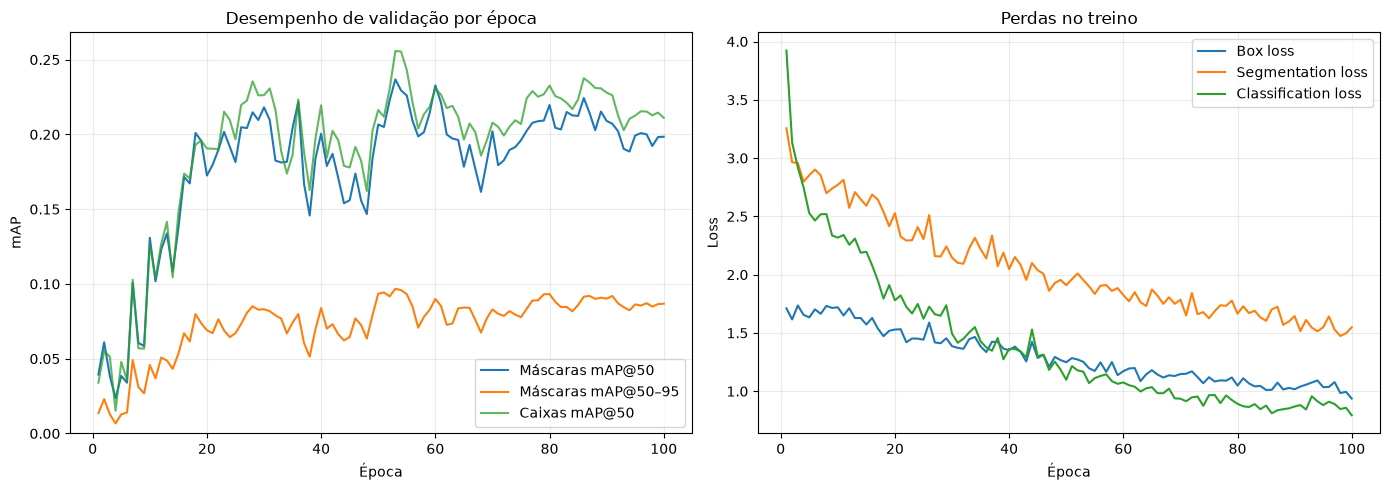

In [2]:
colunas_historico = {
    "Precisão caixas": "metrics/precision(B)",
    "Recall caixas": "metrics/recall(B)",
    "mAP50 caixas": "metrics/mAP50(B)",
    "mAP50-95 caixas": "metrics/mAP50-95(B)",
    "Precisão máscaras": "metrics/precision(M)",
    "Recall máscaras": "metrics/recall(M)",
    "mAP50 máscaras": "metrics/mAP50(M)",
    "mAP50-95 máscaras": "metrics/mAP50-95(M)",
}

colunas_ausentes = [coluna for coluna in colunas_historico.values() if coluna not in historico]
if colunas_ausentes:
    raise KeyError(f"Colunas esperadas não encontradas em results.csv: {colunas_ausentes}")

linha_final = historico.iloc[-1]
linhas_resumo = []
for nome_metrica, coluna in colunas_historico.items():
    indice_melhor = historico[coluna].idxmax()
    linhas_resumo.append(
        {
            "Métrica": nome_metrica,
            "Melhor valor no histórico": historico.loc[indice_melhor, coluna],
            "Época do melhor valor": int(historico.loc[indice_melhor, "epoch"]),
            "Valor na última época": linha_final[coluna],
        }
    )

resumo_historico = pd.DataFrame(linhas_resumo).set_index("Métrica")
display(resumo_historico.style.format({
    "Melhor valor no histórico": "{:.4f}",
    "Valor na última época": "{:.4f}",
}))

fig, eixos = plt.subplots(1, 2, figsize=(14, 5))
eixos[0].plot(historico["epoch"], historico["metrics/mAP50(M)"], label="Máscaras mAP@50")
eixos[0].plot(historico["epoch"], historico["metrics/mAP50-95(M)"], label="Máscaras mAP@50–95")
eixos[0].plot(historico["epoch"], historico["metrics/mAP50(B)"], label="Caixas mAP@50", alpha=0.75)
eixos[0].set(title="Desempenho de validação por época", xlabel="Época", ylabel="mAP")
eixos[0].set_ylim(bottom=0)
eixos[0].grid(alpha=0.25)
eixos[0].legend()

eixos[1].plot(historico["epoch"], historico["train/box_loss"], label="Box loss")
eixos[1].plot(historico["epoch"], historico["train/seg_loss"], label="Segmentation loss")
eixos[1].plot(historico["epoch"], historico["train/cls_loss"], label="Classification loss")
eixos[1].set(title="Perdas no treino", xlabel="Época", ylabel="Loss")
eixos[1].grid(alpha=0.25)
eixos[1].legend()

plt.tight_layout()
plt.show()

In [3]:
modelo_avaliado = YOLO(str(ARQUIVO_BEST))
metricas_validacao = modelo_avaliado.val(
    data=str(ARQUIVO_DATASET),
    split="val",
    plots=False,
    verbose=False,
    workers=0,
    project=str(PASTA_EXECUCAO / "metricas_validacao"),
    name="best_checkpoint",
    exist_ok=True,
)

metricas_gerais = pd.DataFrame(
    [
        {
            "Tipo": tipo,
            "Precisão": avaliacao.mp,
            "Recall": avaliacao.mr,
            "mAP@50": avaliacao.map50,
            "mAP@50–95": avaliacao.map,
        }
        for tipo, avaliacao in (("Caixas", metricas_validacao.box), ("Máscaras", metricas_validacao.seg))
    ]
).set_index("Tipo")
display(metricas_gerais.style.format("{:.4f}"))

def tabela_por_classe(avaliacao, nomes_classes):
    linhas = []
    for posicao, indice_classe in enumerate(avaliacao.ap_class_index):
        indice_classe = int(indice_classe)
        linhas.append(
            {
                "ID": indice_classe,
                "Classe": nomes_classes[indice_classe],
                "Precisão": avaliacao.p[posicao],
                "Recall": avaliacao.r[posicao],
                "mAP@50": avaliacao.ap50[posicao],
                "mAP@50–95": avaliacao.ap[posicao].mean(),
            }
        )
    return pd.DataFrame(linhas).set_index("ID")

print("Desempenho por classe: caixas")
display(tabela_por_classe(metricas_validacao.box, modelo_avaliado.names).style.format("{:.4f}", subset=["Precisão", "Recall", "mAP@50", "mAP@50–95"]))
print("Desempenho por classe: máscaras")
display(tabela_por_classe(metricas_validacao.seg, modelo_avaliado.names).style.format("{:.4f}", subset=["Precisão", "Recall", "mAP@50", "mAP@50–95"]))

quantidades_split = []
for split in ("train", "val"):
    pasta_imagens = PASTA_PROJETO / "dataset" / "images" / split
    pasta_rotulos = PASTA_PROJETO / "dataset" / "labels" / split
    imagens_split = [
        arquivo for arquivo in pasta_imagens.iterdir()
        if arquivo.is_file() and arquivo.suffix.casefold() in {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff", ".avif"}
    ]
    rotulos_vazios = sum(
        (pasta_rotulos / f"{imagem.stem}.txt").is_file()
        and (pasta_rotulos / f"{imagem.stem}.txt").stat().st_size == 0
        for imagem in imagens_split
    )
    quantidades_split.append(
        {"Divisão": split, "Imagens": len(imagens_split), "Exemplos negativos": rotulos_vazios}
    )
print("Composição das divisões")
display(pd.DataFrame(quantidades_split).set_index("Divisão"))

Ultralytics 8.4.165  Python-3.12.2 torch-2.14.0+cpu CPU (AMD Ryzen 7 5700U with Radeon Graphics)
YOLOv8n-seg summary (fused): 85 layers, 3,258,649 parameters, 0 gradients, 11.3 GFLOPs
val: Fast image access  (ping: 0.40.6 ms, read: 251.1296.1 MB/s, size: 959.0 KB)
val: Scanning C:\Users\alexa\Downloads\Teste Base de Imagens TCC\dataset\labels\val.cache... 29 images, 8 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 29/29  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.5s/it 4.9s9.6s
                   all         29         83      0.797      0.227      0.243       0.12      0.787      0.204      0.226     0.0933
Speed: 3.7ms preprocess, 97.5ms inference, 0.0ms loss, 33.6ms postprocess per image


,Precisão,Recall,mAP@50,mAP@50–95
Tipo,,,,
Caixas,0.7974,0.2266,0.2431,0.1199
Máscaras,0.7873,0.2037,0.2264,0.0933


Desempenho por classe: caixas


,Classe,Precisão,Recall,mAP@50,mAP@50–95
ID,,,,,
0,lixo_solto,0.5949,0.4532,0.4858,0.2397
2,entulho,1.0000,0.0000,0.0003,0.0001


Desempenho por classe: máscaras


,Classe,Precisão,Recall,mAP@50,mAP@50–95
ID,,,,,
0,lixo_solto,0.5746,0.4074,0.4527,0.1865
2,entulho,1.0000,0.0000,0.0000,0.0000


Composição das divisões


,Imagens,Exemplos negativos
Divisão,,
train,117,25
val,29,8


In [4]:
from collections import Counter

rotulos_validacao = PASTA_PROJETO / "dataset" / "labels" / "val"
instancias_por_classe = Counter()
for arquivo_rotulo in rotulos_validacao.glob("*.txt"):
    for linha in arquivo_rotulo.read_text(encoding="utf-8").splitlines():
        if linha.strip():
            instancias_por_classe[int(linha.split(maxsplit=1)[0])] += 1

linhas_classes = []
for indice_classe, nome_classe in modelo_avaliado.names.items():
    linha = {
        "ID": indice_classe,
        "Classe": nome_classe,
        "Instâncias na validação": instancias_por_classe[indice_classe],
    }
    for sufixo, avaliacao in (("Caixas", metricas_validacao.box), ("Máscaras", metricas_validacao.seg)):
        posicoes = [
            posicao for posicao, classe in enumerate(avaliacao.ap_class_index)
            if int(classe) == indice_classe
        ]
        if posicoes:
            posicao = posicoes[0]
            linha[f"Precisão {sufixo}"] = avaliacao.p[posicao]
            linha[f"Recall {sufixo}"] = avaliacao.r[posicao]
            linha[f"mAP@50 {sufixo}"] = avaliacao.ap50[posicao]
            linha[f"mAP@50–95 {sufixo}"] = avaliacao.ap[posicao].mean()
        else:
            linha[f"Precisão {sufixo}"] = float("nan")
            linha[f"Recall {sufixo}"] = float("nan")
            linha[f"mAP@50 {sufixo}"] = float("nan")
            linha[f"mAP@50–95 {sufixo}"] = float("nan")
    linhas_classes.append(linha)

detalhe_por_classe = pd.DataFrame(linhas_classes).set_index("ID")
display(detalhe_por_classe.style.format("{:.4f}", na_rep="N/A", subset=[coluna for coluna in detalhe_por_classe.columns if coluna != "Classe" and coluna != "Instâncias na validação"]))

arquivo_csv_classes = PASTA_EXECUCAO / "metricas_por_classe.csv"
arquivo_csv_gerais = PASTA_EXECUCAO / "metricas_gerais_best.csv"
detalhe_por_classe.to_csv(arquivo_csv_classes, encoding="utf-8-sig")
metricas_gerais.to_csv(arquivo_csv_gerais, encoding="utf-8-sig")
print(f"Métricas por classe exportadas para: {arquivo_csv_classes}")
print(f"Métricas gerais exportadas para: {arquivo_csv_gerais}")

,Classe,Instâncias na validação,Precisão Caixas,Recall Caixas,mAP@50 Caixas,mAP@50–95 Caixas,Precisão Máscaras,Recall Máscaras,mAP@50 Máscaras,mAP@50–95 Máscaras
ID,,,,,,,,,,
0,lixo_solto,81,0.5949,0.4532,0.4858,0.2397,0.5746,0.4074,0.4527,0.1865
1,lixo_contido,0,N/A,N/A,N/A,N/A,N/A,N/A,N/A,N/A
2,entulho,2,1.0000,0.0000,0.0003,0.0001,1.0000,0.0000,0.0000,0.0000


Métricas por classe exportadas para: c:\Users\alexa\Downloads\Teste Base de Imagens TCC\runs\segment\yolo_lixo_urbano-2\metricas_por_classe.csv
Métricas gerais exportadas para: c:\Users\alexa\Downloads\Teste Base de Imagens TCC\runs\segment\yolo_lixo_urbano-2\metricas_gerais_best.csv


## Leitura crítica dos resultados

- Um recall baixo significa que parte dos objetos anotados não foi detectada; portanto, uma precisão alta isoladamente não significa que o modelo esteja encontrando a maior parte do lixo.
- `lixo_contido` não possui polígonos anotados no dataset atual. Métricas dessa classe não podem ser calculadas de forma confiável até que existam exemplos rotulados suficientes nas divisões de treino e validação.
- `entulho` tem poucos exemplos (13 polígonos no total, com apenas 2 instâncias na validação anterior). Suas métricas são muito instáveis e não permitem concluir que o modelo reconhece bem essa classe.
- A validação contém somente 29 imagens, então pequenas mudanças nas previsões podem alterar bastante os indicadores. Para avaliar generalização, reserve imagens independentes de teste e aumente as anotações, sobretudo para `lixo_contido` e `entulho`.
- A tabela de histórico mostra o melhor valor observado em cada métrica; esses máximos podem ocorrer em épocas diferentes. A avaliação por classe acima é recalculada usando `best.pt`, que é o checkpoint selecionado pelo Ultralytics.

O diretório de execução também contém curvas Precision-Recall, curvas F1, matriz de confusão, previsões da validação e `results.csv`, úteis para inspeção complementar.